# DANDI 000568 | Real Optogenetic Event & Neural Alignment Audit

**Research question:** Can we recover genuine optogenetic ON/OFF pulse times and align them with hippocampal spike data, without downloading the 904.8 GB Dandiset?

- Published Dandiset **000568**, version **0.230705.1633**.
- Uses **two small `no-raw-data` NWB copies** for `fCamk1` sessions (about 29 and 44 MB). These omit large raw electrical traces but may contain spike sorting and optogenetic event records.
- This dataset concerns **pulsed excitation in freely moving mice**, **not human epilepsy**, and it **cannot establish seizure suppression**.
- We **never invent stimulus events** when a timestamp or offset is missing. All missing items remain explicitly unverified.

Sources:
- https://dandiarchive.org/dandiset/000568
- https://api.dandiarchive.org/api/dandisets/000568/versions/0.230705.1633/assets/
- Valero et al., Science 2022, https://doi.org/10.1126/science.abm1891

**Kaggle:** Internet ON. Accelerator None. No input needed. Run all. Get `dandi000568_alignment_results.zip` from `/kaggle/working/`.


## 1 — Setup and published metadata

In [1]:
import sys, subprocess, importlib.util
for pkg in ["requests", "h5py", "numpy", "pandas", "matplotlib"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import requests, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt
import json, re, zipfile, traceback
from pathlib import Path
from datetime import datetime, timezone

DANDISET_ID = "000568"
VERSION = "0.230705.1633"
BASE = "https://api.dandiarchive.org"
OUT = Path("/kaggle/working/dandi000568_alignment_audit") if Path("/kaggle/working").exists() else Path("/mnt/data/dandi000568_alignment_audit")
CACHE = OUT / "nwb_cache"
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
DOWNLOAD_TWO = True    # set False to audit just one ~29 MB NWB first
MAX_FILE_MB = 65         # safety: never download full raw recordings accidentally
print("Output directory:", OUT)
print("This is an audit, not model training.")

Output directory: /kaggle/working/dandi000568_alignment_audit
This is an audit, not model training.


## 2 — Retrieve the pinned manifest (metadata only)

In [2]:
def get_json(url, timeout=45):
    r = requests.get(url, headers={"Accept": "application/json"}, timeout=timeout)
    r.raise_for_status()
    return r.json()

manifest = []
next_url = f"{BASE}/api/dandisets/{DANDISET_ID}/versions/{VERSION}/assets/"
while next_url:
    payload = get_json(next_url)
    manifest.extend(payload["results"])
    next_url = payload.get("next")
print("Manifest assets:", len(manifest))
assets = pd.DataFrame([{"asset_id":a["asset_id"], "path":a["path"],
                        "size_bytes":a["size"], "size_MB":round(a["size"]/1e6,2),
                        "subject":a["path"].split("/")[0]} for a in manifest])
assets.to_csv(OUT/"manifest.csv", index=False)
asset_nwb = assets[assets.path.str.endswith(".nwb")].copy()
opto_files = asset_nwb[asset_nwb.path.str.contains("+ogen",regex=False)].copy()
small = opto_files[opto_files.path.str.contains("no-raw-data")].sort_values("size_bytes").copy()
print("NWB files:",len(asset_nwb),"Explicit '+ogen' NWB files:",len(opto_files))
print("Subjects with explicit '+ogen' filename:",opto_files.subject.unique().tolist())
print("Small metadata-only candidates:")
print(small[["path","size_MB"]].to_string(index=False))
if small.empty:
    raise RuntimeError("No small +ogen NWB files found in pinned manifest; stop rather than download large files.")

Manifest assets: 138
NWB files: 56 Explicit '+ogen' NWB files: 4
Subjects with explicit '+ogen' filename: ['sub-fCamk1']
Small metadata-only candidates:
                                                                                      path  size_MB
sub-fCamk1/sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb    28.68
 sub-fCamk1/sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb    44.44


## 3 — Download only the small NWB copies (not full Dandiset)

In [3]:
selected = small.head(2 if DOWNLOAD_TWO else 1).copy()

def safe_download(row):
    name = row["path"].rsplit("/",1)[-1]
    target = CACHE/name
    expected = int(row["size_bytes"])
    assert expected <= MAX_FILE_MB*1e6, f"Large download prevented: {expected/1e6:.1f} MB"
    if target.exists() and target.stat().st_size == expected:
        print("Reuse cached:", name)
        return target
    url = f"{BASE}/api/assets/{row['asset_id']}/download/"
    tmp = target.with_suffix(target.suffix+".part")
    with requests.get(url,stream=True,timeout=(30,180)) as resp:
        resp.raise_for_status()
        with tmp.open("wb") as f:
            for chunk in resp.iter_content(chunk_size=1024*1024):
                if chunk: f.write(chunk)
    actual = tmp.stat().st_size
    if actual != expected:
        raise IOError(f"Download size mismatch for {name}: got {actual}, expected {expected}")
    tmp.replace(target)
    print("Downloaded:",name, "MB:",round(expected/1e6,2))
    return target

local_files = {}
download_errors = {}
for _,row in selected.iterrows():
    try:
        p=safe_download(row)
        local_files[row["path"]] = str(p)
    except Exception as exc:
        download_errors[row["path"]] = f"{type(exc).__name__}: {exc}"
        print("Download failed:",row["path"],download_errors[row["path"]])
print("Files available:",len(local_files),"Failures:",len(download_errors))

Downloaded: sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb MB: 28.68
Downloaded: sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb MB: 44.44
Files available: 2 Failures: 0


## 4 — Inspect NWB structure and find real optogenetic series

In [4]:
def attr_text(x):
    if isinstance(x, bytes): return x.decode("utf-8","replace")
    return str(x)

def structure_scan(hf):
    rows=[]
    target_words=("ogen","opto","stim","light","pulse","gpio","units","spike","electrical","lfp","ripple")
    def visit(name,node):
        if not any(w in name.lower() for w in target_words) and not (isinstance(node,h5py.Group) and "Optogenetic" in attr_text(node.attrs.get("neurodata_type",""))):
            return
        rows.append({"path":"/"+name, "kind":"Group" if isinstance(node,h5py.Group) else "Dataset",
                     "shape":str(tuple(node.shape)) if isinstance(node,h5py.Dataset) else "",
                     "neurodata_type":attr_text(node.attrs.get("neurodata_type","")),
                     "unit":attr_text(node.attrs.get("unit",""))})
    hf.visititems(visit)
    return rows

def extract_timeseries(hf, path):
    group=hf[path]
    if not isinstance(group,h5py.Group) or "data" not in group:
        return None, "Missing data"
    data_ds=group["data"]
    if not isinstance(data_ds,h5py.Dataset) or not data_ds.shape:
        return None, "data is not a time-series array"
    n=int(data_ds.shape[0])
    if n>2_000_000:
        return None, f"Time series >2M points: {n}; refused full-array read"
    if "timestamps" in group:
        t=np.asarray(group["timestamps"][:],dtype=float)
        source="timestamps"
    elif "starting_time" in group:
        start=float(group["starting_time"][()])
        rate=group["starting_time"].attrs.get("rate",None)
        if rate is None or float(rate)<=0:
            return None, "starting_time available but valid rate missing"
        t=start + np.arange(n,dtype=float)/float(rate)
        source="starting_time+rate"
    else:
        return None,"No timestamps or starting_time/rate"
    if len(t)!=n: return None, f"Time/data length mismatch: {len(t)}, {n}"
    arr=np.asarray(data_ds[:],dtype=float)
    if arr.ndim>1:
        mag=np.nanmax(arr.reshape((n,-1)),axis=1)
    else: mag=arr
    return (t,mag,source,attr_text(data_ds.attrs.get("unit", group.attrs.get("unit","unknown")))),None

def find_opto_paths(hf):
    candidates=[]
    def visitor(name,node):
        if isinstance(node,h5py.Group):
            nt=attr_text(node.attrs.get("neurodata_type",""))
            if nt=="OptogeneticSeries" or ("opto" in name.lower() or "ogen" in name.lower()) and "data" in node and ("timestamps" in node or "starting_time" in node):
                candidates.append("/"+name)
    hf.visititems(visitor)
    return sorted(set(candidates))

all_structure=[]
opto_inventory=[]
all_events=[]
all_timeseries=[]
for path,local_path in local_files.items():
    try:
        with h5py.File(local_path,"r") as hf:
            for r in structure_scan(hf): all_structure.append({"asset_path":path,**r})
            print("\n",path)
            print("Top-level NWB groups:",list(hf.keys()))
            found=find_opto_paths(hf)
            print("Candidate optogenetic series:",found)
            for gp in found:
                series,error=extract_timeseries(hf,gp)
                row={"asset_path":path,"series":gp,"error":error}
                if series is not None:
                    t,pow_,source,unit=series
                    ison=np.isfinite(pow_) & (pow_>0)
                    starts=np.flatnonzero(ison & ~np.r_[False,ison[:-1]])
                    ends=np.flatnonzero(~ison & np.r_[False,ison[:-1]])
                    if ison.size and ison[0]: starts=starts[1:] if len(starts) else starts # start already ON: left-censored
                    # Only use complete ON->OFF transitions. Do not invent pulse offsets.
                    events=[]
                    for ix in starts:
                        later=ends[ends>ix]
                        if len(later)==0: continue
                        j=int(later[0])
                        if not np.isfinite(t[ix]) or not np.isfinite(t[j]): continue
                        events.append({"asset_path":path,"series":gp,"onset_sec":float(t[ix]),
                                       "offset_sec":float(t[j]),"duration_sec":float(t[j]-t[ix]),
                                       "on_value":float(pow_[ix]),"reported_unit":unit})
                    all_events.extend(events)
                    row.update({"time_source":source,"unit":unit,"samples":len(t),
                                "start_sec":float(t[0]) if len(t) else None,
                                "end_sec":float(t[-1]) if len(t) else None,
                                "positive_samples":int(ison.sum()),"complete_events":len(events),
                                "distinct_positive_values":str(np.unique(pow_[ison])[:12].tolist())})
                    # Short preview for diagnosis (not full raw data)
                    for k in range(min(400,len(t))):
                        all_timeseries.append({"asset_path":path,"series":gp,"time_sec":float(t[k]),"value":float(pow_[k])})
                opto_inventory.append(row)
    except Exception as exc:
        opto_inventory.append({"asset_path":path,"error":f"{type(exc).__name__}: {exc}"})
        print("NWB inspection error:",type(exc).__name__,str(exc))

pd.DataFrame(all_structure).to_csv(OUT/"nwb_structure.csv",index=False)
pd.DataFrame(opto_inventory).to_csv(OUT/"optogenetic_series_inventory.csv",index=False)
pd.DataFrame(all_events).to_csv(OUT/"optogenetic_pulse_events.csv",index=False)
pd.DataFrame(all_timeseries).to_csv(OUT/"optogenetic_series_preview.csv",index=False)
print("Complete optical ON/OFF events:",len(all_events))


 sub-fCamk1/sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb
Top-level NWB groups: ['acquisition', 'analysis', 'file_create_date', 'general', 'identifier', 'intervals', 'processing', 'session_description', 'session_start_time', 'specifications', 'stimulus', 'timestamps_reference_time', 'units']
Candidate optogenetic series: ['/stimulus/presentation/OptogeneticSeriesSite3', '/stimulus/presentation/OptogeneticSeriesSite4', '/stimulus/presentation/OptogeneticSeriesSite5', '/stimulus/presentation/OptogeneticSeriesSite6', '/stimulus/presentation/OptogeneticSeriesSite7', '/stimulus/presentation/OptogeneticSeriesSite8']

 sub-fCamk1/sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb
Top-level NWB groups: ['acquisition', 'analysis', 'file_create_date', 'general', 'identifier', 'intervals', 'processing', 'session_description', 'session_start_time', 'specifications', 'stimulus', 'timestamps_reference_time', 'units']
Candidate optogeneti

## 5 — Check neural spike trains and synchronization (no invented labels)

sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb units groups: ['/units']
sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb units groups: ['/units']
In-span pulse-response pairs: 1000


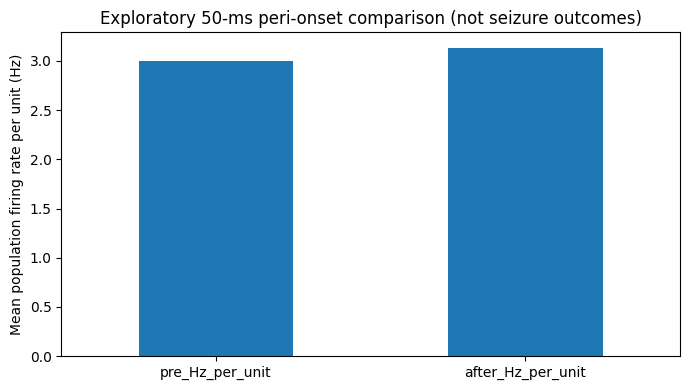

In [5]:
def find_units_group(hf):
    paths=[]
    def visit(name,node):
        if isinstance(node,h5py.Group) and "spike_times" in node and "spike_times_index" in node:
            paths.append("/"+name)
    hf.visititems(visit)
    return paths

spike_inventories=[]
alignment=[]
all_analysis=[]
event_df=pd.DataFrame(all_events)
for path,local_path in local_files.items():
    try:
        with h5py.File(local_path,"r") as hf:
            units_paths=find_units_group(hf)
            print(path.split("/")[-1],"units groups:",units_paths)
            for gp in units_paths:
                group=hf[gp]
                spikes=np.asarray(group["spike_times"][:],dtype=float)
                ends=np.asarray(group["spike_times_index"][:],dtype=int)
                n_units=len(ends)
                low=float(np.nanmin(spikes)) if len(spikes) else None
                high=float(np.nanmax(spikes)) if len(spikes) else None
                spike_inventories.append({"asset_path":path,"units_group":gp,"n_units":n_units,
                                          "n_spikes":len(spikes),"min_spike_time":low,"max_spike_time":high})
                if event_df.empty: continue
                e=event_df[event_df["asset_path"]==path].copy()
                if len(e)==0 or low is None or high is None: continue
                in_span=e[(e.onset_sec>=low) & (e.offset_sec<=high)].copy()
                alignment.append({"asset_path":path,"units_group":gp,"complete_events":len(e),
                                  "events_in_spike_time_span":len(in_span),"fraction_in_span":len(in_span)/len(e),
                                  "time_overlap_indicates_alignment_only":True})
                # Exploratory population spike-rate response, each complete pulse gets its own pre/on window.
                if not in_span.empty and len(spikes):
                    spikes=np.sort(spikes[np.isfinite(spikes)])
                    W=0.05 # seconds; for pulsed optogenetics look 50 ms before and after onset
                    for _,ev in in_span.head(500).iterrows():
                        a=float(ev.onset_sec)
                        bcount=int(np.searchsorted(spikes,a,side="left")-np.searchsorted(spikes,a-W,side="left"))
                        pcount=int(np.searchsorted(spikes,a+W,side="left")-np.searchsorted(spikes,a,side="left"))
                        all_analysis.append({"asset_path":path,"units_group":gp,"onset_sec":a,
                                             "pre_50ms_count":bcount,"after_onset_50ms_count":pcount,
                                             "pre_Hz_per_unit":bcount/W/max(n_units,1),
                                             "after_Hz_per_unit":pcount/W/max(n_units,1)})
    except Exception as exc:
        spike_inventories.append({"asset_path":path,"error":f"{type(exc).__name__}: {exc}"})
        print("Spike inspection error:",exc)

pd.DataFrame(spike_inventories).to_csv(OUT/"neural_units_inventory.csv",index=False)
pd.DataFrame(alignment).to_csv(OUT/"time_alignment_check.csv",index=False)
pd.DataFrame(all_analysis).to_csv(OUT/"pulse_triggered_neural_response_EXPLORATORY.csv",index=False)
print("In-span pulse-response pairs:",len(all_analysis))
if all_analysis:
    adf=pd.DataFrame(all_analysis)
    means=adf[["pre_Hz_per_unit","after_Hz_per_unit"]].mean()
    ax=means.plot(kind="bar",figsize=(7,4),rot=0)
    ax.set_ylabel("Mean population firing rate per unit (Hz)")
    ax.set_title("Exploratory 50-ms peri-onset comparison (not seizure outcomes)")
    plt.tight_layout()
    plt.savefig(OUT/"exploratory_neural_response.png",dpi=170)
    plt.show()
else:
    print("No time-aligned neural response computed; this is a legitimate audit outcome.")

## 6 — Feasibility report and a ZIP to upload back to ChatGPT

In [6]:
success_series = [r for r in opto_inventory if r.get("error") is None and r.get("time_source")]
report={
    "study":"DANDI 000568, version 0.230705.1633",
    "run_utc":datetime.now(timezone.utc).isoformat(),
    "published_dandiset_subjects":4,
    "explicit_ogen_filename_subjects":sorted(opto_files.subject.unique().tolist()),
    "selected_nwb_files":selected.path.tolist(),
    "downloaded_nwb_files":list(local_files),
    "download_errors":download_errors,
    "optogenetic_series_readable":len(success_series),
    "complete_on_off_events":len(all_events),
    "verified_pulse_neural_time_pairs":len(all_analysis),
    "neural_units_inventories":spike_inventories,
    "alignment_summary":alignment,
    "scope_warning":"Mouse hippocampus, pulsed excitation; not human epilepsy or suppression therapy.",
    "limitations":["+ogen appears explicitly under fCamk1 only in published asset filenames; audit other subjects before generalization.",
                   "no-raw-data NWB files omit large raw traces; useful for event/spike validation but not full raw LFP modeling.",
                   "OptogeneticSeries presence does not by itself prove valid ON/OFF intervals or shared spike clock.",
                   "Only verified complete events can become input labels; never fabricate offsets or per-trial intensity."],
}
report["provisional_gate"]=(
    "PASS_for_mouse_method_testing" if len(all_analysis)>0 else
    "NEEDS_REVIEW_optical_events_found" if len(all_events)>0 else
    "FAIL_OR_UNVERIFIED_no_complete_optical_events"
)
(OUT/"feasibility_report.json").write_text(json.dumps(report,indent=2,default=str))
print(json.dumps({k:report[k] for k in ["published_dandiset_subjects","explicit_ogen_filename_subjects","optogenetic_series_readable","complete_on_off_events","verified_pulse_neural_time_pairs","provisional_gate"]},indent=2))

# zip only output tables and figures, NOT the NWB blobs
zip_target=OUT.parent/"dandi000568_alignment_results.zip"
with zipfile.ZipFile(zip_target,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.glob("*"):
        if p.is_file(): z.write(p,arcname=p.name)
print("OUTPUT ZIP:", zip_target)
print("Upload the ZIP back in chat so we can confirm actual timing, pulse counts, and whether model training is feasible.")

{
  "published_dandiset_subjects": 4,
  "explicit_ogen_filename_subjects": [
    "sub-fCamk1"
  ],
  "optogenetic_series_readable": 12,
  "complete_on_off_events": 92397,
  "verified_pulse_neural_time_pairs": 1000,
  "provisional_gate": "PASS_for_mouse_method_testing"
}
OUTPUT ZIP: /kaggle/working/dandi000568_alignment_results.zip
Upload the ZIP back in chat so we can confirm actual timing, pulse counts, and whether model training is feasible.


### How to interpret the result

- **PASS_for_mouse_method_testing:** At least one complete light ON→OFF interval overlaps with recorded spikes, and the notebook measured a response. This is a **data-alignment** result only, not proof of efficacy.
- **NEEDS_REVIEW_optical_events_found:** Light events exist, but matched spike trains were not found or the clocks did not overlap.
- **FAIL_OR_UNVERIFIED_no_complete_optical_events:** We found no complete usable optical events in the inspected subset. Inspect the NWB internals and other datasets before training.

**Scientific caution:** The study used optogenetic excitation in healthy mice, not epileptiform-activity suppression. Even if timing is valid, this dataset is a **method-testing benchmark**, not a replacement for human epilepsy data.
